# Urban Green Space Accessibility & Equity — Barcelona


> **Status: experiment** Structure, function boundaries and outputs are designed so approved cells can be lifted into a deployable pipeline (ingest → process → score → publish).

### Why Barcelona?
| Criterion | Barcelona |
|---|---|
| Comparable unit count | 73 *barris* (Chicago: 77 community areas) |
| Open APIs for every layer | Open Data BCN (CKAN API): boundaries, Padró population, household income. OpenStreetMap (Overpass API): green polygons, metro/rail stations, buildings |
| Likely to benefit | A very dense city with a well-documented north-south / centre-periphery income gradient, little space to add new parks, and heat-vulnerability concerns that make *where* a new green space goes decisive |
| Spatial detail | Barri-level income exists, so the "low-income" objective can be reproduced |

### Objective map
| Objective | Meaning |
|---|---|
| Obj. 1 | green park distribution + metro/rail stations |
| Obj. 2 | % green coverage choropleth |
| Obj. 3 | population density choropleth |
| Obj. 4.1 | population per unit of green area (shown as m² per inhabitant too) |
| Obj. 4.2 | income-based equity view (see note on proxy) |
| Obj. 5 | Accessibility Score, ranking, priority index, sensitivity |

## 0. Methodological workflow

## 1. Setup & configuration

In [11]:
# Import Libraries

import io, json, re, time, unicodedata, warnings
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy.stats import spearmanr
import osmnx as ox
from IPython.display import display

try:
    import contextily as ctx
except ImportError:
    ctx = None

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 160, "display.max_columns", 40)

CFG = dict(
    CITY="Barcelona",
    CRS_WGS84="EPSG:4326",
    CRS_PROJ="EPSG:25831",          # metric CRS for Barcelona (ETRS89 / UTM 31N)
    CKAN="https://opendata-ajuntament.barcelona.cat/data/api/3/action",
    # CKAN package ids (verified at run time; falls back to a search if not found)
    PKG_BOUNDARIES=["20170706-districtes-barris"],
    PKG_POPULATION=["pad_mdbas", "pad_mdbas_sexe"],
    PKG_INCOME=["renda-disponible-llars-bcn"],
    PKG_PARKS_OFFICIAL=["culturailleure-parcsjardins"],
    # Green-space definition
    INCLUDE_FOREST=False,           # natural=wood / scrub (Collserola) excluded from *urban* green by default
    MIN_GREEN_M2=100,               # drop slivers
    # Accessibility standards
    NEAR_DIST_M=300, NEAR_MIN_M2=5_000,      # >=0.5 ha within 300 m (EU / 3-30-300 style)
    LARGE_DIST_M=1_000, LARGE_MIN_M2=50_000, # >=5 ha within 1 km (district park)
    WHO_TARGET_M2_PP=9,             # commonly cited minimum m² of green per inhabitant
    # Sampling of where residents live
    POINTS="buildings",             # "buildings" (footprint-weighted) or "grid" (fallback)
    GRID_STEP_M=50, MIN_BUILDING_M2=40,
    # Equity
    LOW_INCOME_INDEX=75,            # barri income < 75% of city (population-weighted) average = "low income"
    # Score weights (must be approved by stakeholders before production use)
    WEIGHTS=dict(c_percapita=0.30, c_prox300=0.35, c_large1km=0.15, c_coverage=0.20),
    PRIORITY_WEIGHTS=dict(access_need=0.50, density=0.25, income_need=0.25),
    REFRESH=False,                  # True = ignore cached API responses
)

ROOT = Path("data"); RAW = ROOT / "raw"; OUT = ROOT / "outputs"; MAPS = OUT / "maps"
for p in (RAW, OUT, MAPS):
    p.mkdir(parents=True, exist_ok=True)

PROV = {"city": CFG["CITY"], "run_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"), "sources": {}}
ox.settings.use_cache = True
ox.settings.timeout = 300

## 2. API helpers
Open Data BCN is a **CKAN** portal (`package_search`, `package_show`, `datastore_search`). OpenStreetMap is queried through the **Overpass API** (via `osmnx`). Resources are *discovered* through the API rather than hard-coded, and every cell that reads a table validates its schema.

In [12]:
SESSION = requests.Session()
SESSION.mount("https://", HTTPAdapter(max_retries=Retry(total=4, backoff_factor=1.5,
                                                         status_forcelist=(429, 500, 502, 503, 504))))
SESSION.headers["User-Agent"] = "green-access-notebook/0.1 (academic research)"

def norm(s):
    """lower-case ascii snake_case, used to match column / resource names robustly"""
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode().lower()
    return re.sub(r"[^a-z0-9]+", "_", s).strip("_")

def find_col(df, patterns, required=True):
    cols = {norm(c): c for c in df.columns}
    for p in patterns:                       # exact matches first
        if p in cols: return cols[p]
    for p in patterns:                       # then substring matches
        for n, c in cols.items():
            if p in n: return c
    if required:
        raise KeyError(f"None of {patterns} found. Available columns: {list(df.columns)}")
    return None

def ckan(action, **params):
    r = SESSION.get(f"{CFG['CKAN']}/{action}", params=params, timeout=90)
    r.raise_for_status()
    j = r.json()
    if not j.get("success"):
        raise RuntimeError(f"CKAN {action} failed: {j}")
    return j["result"]

def search_packages(q, rows=10):
    res = ckan("package_search", q=q, rows=rows)
    return pd.DataFrame([{"name": p["name"], "title": p["title"], "n_resources": len(p["resources"])}
                         for p in res["results"]])

def list_resources(package_id):
    pkg = ckan("package_show", id=package_id)
    return pd.DataFrame([{"id": r["id"], "name": r.get("name"), "format": (r.get("format") or "").lower(),
                          "url": r.get("url"), "datastore_active": bool(r.get("datastore_active"))}
                         for r in pkg["resources"]])

def resolve_package(candidates, search_query):
    for c in candidates:
        try:
            ckan("package_show", id=c); return c
        except Exception:
            continue
    hits = search_packages(search_query)
    display(hits)
    if hits.empty:
        raise RuntimeError(f"No CKAN package found for {candidates} / '{search_query}'")
    print(f"WARNING: {candidates} not found - using best search hit '{hits.iloc[0]['name']}'. Verify!")
    return hits.iloc[0]["name"]

def latest_resource(res, formats=("csv",), target_year=None):
    r = res[res["format"].isin(formats)].copy()
    if r.empty:
        raise RuntimeError(f"No resource with format {formats}. Available: {res['format'].unique()}")
    def yr(name):
        m = re.findall(r"(?<!\d)(?:19|20)\d{2}(?!\d)", str(name))
        return max(map(int, m)) if m else 0
    r["year"] = r["name"].map(yr)                          # year from the NAME only (URLs contain random ids)
    if target_year is not None and (r["year"] > 0).any():
        r["gap"] = (r["year"] - target_year).abs()
        return r.sort_values(["gap", "year"], ascending=[True, False]).iloc[0]
    return r.sort_values("year", ascending=False).iloc[0]

def datastore_all(resource_id, page=10_000):
    out, offset = [], 0
    while True:
        res = ckan("datastore_search", resource_id=resource_id, limit=page, offset=offset)
        out += res["records"]
        if len(res["records"]) < page: break
        offset += page
    return pd.DataFrame(out).drop(columns=["_id", "_full_text"], errors="ignore")

def download_bytes(url):
    r = SESSION.get(url, timeout=180, allow_redirects=True)
    r.raise_for_status()
    return r.content

def read_resource_table(row):
    if row["datastore_active"]:
        return datastore_all(row["id"])
    raw = download_bytes(row["url"])
    for enc in ("utf-8-sig", "latin-1"):
        try:
            return pd.read_csv(io.BytesIO(raw), encoding=enc)
        except UnicodeDecodeError:
            continue
    raise ValueError(f"Could not decode CSV from {row['url']}")

def read_geo_url(url):
    """Download first, then parse. CKAN '/download' URLs have no file extension, so GDAL cannot sniff them remotely."""
    raw = download_bytes(url)
    if raw[:2] == b"PK":                                       # zipped shapefile
        tmp = RAW / "_download.zip"; tmp.write_bytes(raw)
        g = gpd.read_file(f"zip://{tmp.resolve().as_posix()}")
    elif raw.lstrip()[:1] in (b"{", b"["):                     # GeoJSON
        obj = json.loads(raw.decode("utf-8-sig"))
        feats = obj["features"] if isinstance(obj, dict) else obj
        g = gpd.GeoDataFrame.from_features(feats)
    else:
        raise ValueError(f"Unrecognised geo format, content starts with {raw[:60]!r}")
    if g.crs is None:                                          # guess CRS from coordinate magnitude
        minx, miny, maxx, maxy = g.total_bounds
        g = g.set_crs(CFG["CRS_WGS84"] if max(abs(minx), abs(maxx)) <= 180 else CFG["CRS_PROJ"])
    return g

def unary(geoms):
    return geoms.union_all() if hasattr(geoms, "union_all") else geoms.unary_union

def valid(g):
    g = g.copy()
    g["geometry"] = gpd.GeoSeries(shapely.make_valid(np.asarray(g.geometry.values)), index=g.index, crs=g.crs)
    return g

## 3. Data acquisition

### 3.1 Barri boundaries, population, income (Open Data BCN – CKAN)

In [13]:
# Helper Function

def year_of(s):
    """Year as int from either plain years (2023) or date strings ('2012-01-01T00:00:00')."""
    num = pd.to_numeric(s, errors="coerce")
    if num.notna().all():
        return num.astype(int)
    return pd.to_datetime(s, errors="coerce").dt.year

In [14]:
def load_barris():
    pkg = resolve_package(CFG["PKG_BOUNDARIES"], "districtes barris limits administratius")
    res = list_resources(pkg)
    cand = res[res["name"].map(norm).str.contains("barri") | res["url"].map(norm).str.contains("barri")]
    if cand.empty:
        display(res); raise RuntimeError("No 'barri' boundary resource found - inspect the table above.")
    
    g, row = None, None
    for _, r_ in cand[cand["format"].isin(["geojson", "json"])].iterrows():
        try:
            g, row = read_geo_url(r_["url"]), r_; break
        except Exception as e:
            print(f"skipping '{r_['name']}': {type(e).__name__}: {e}")
    if g is None:
        row = latest_resource(cand, ("csv",)); df = read_resource_table(row)
        wkt = find_col(df, ["geometria_wgs84", "geometry_wgs84", "wkt", "geometry", "geometria", "geometria_etrs89"])
        crs = CFG["CRS_PROJ"] if "etrs89" in norm(wkt) else CFG["CRS_WGS84"]
        g = gpd.GeoDataFrame(df.drop(columns=[wkt]), geometry=gpd.GeoSeries.from_wkt(df[wkt]), crs=crs)
    
    PROV["sources"]["boundaries"] = {"package": pkg, "resource": row["name"], "url": row["url"]}
    code_col = find_col(g, ["codi_barri", "barri", "codi"])
    name_col = find_col(g, ["nom_barri", "nom"])
    out = gpd.GeoDataFrame({
        "barri_code": pd.to_numeric(g[code_col], errors="coerce").astype("Int64"),
        "barri": g[name_col].astype(str),
        "district": g[find_col(g, ["nom_districte", "districte"], required=False)].astype(str)
                    if find_col(g, ["nom_districte", "districte"], required=False) else "",
        "geometry": g.geometry}, crs=g.crs)
    return valid(out.dropna(subset=["barri_code"]).to_crs(CFG["CRS_PROJ"]))

def load_population(target_year=None):
    pkg = resolve_package(CFG["PKG_POPULATION"], "padro poblacio barris")
    row = latest_resource(list_resources(pkg), target_year=target_year); df = read_resource_table(row)
    code_c = find_col(df, ["codi_barri", "barri"]); val_c = find_col(df, ["valor", "poblacio", "nombre", "habitants", "total"])
    year_c = find_col(df, ["any", "year", "data_referencia"], required=False)
    df["_v"] = pd.to_numeric(df[val_c], errors="coerce")
    if year_c is not None:
        yr = year_of(df[year_c]); df = df[yr == yr.max()]
    out = (df.assign(barri_code=pd.to_numeric(df[code_c], errors="coerce"))
             .dropna(subset=["barri_code"]).groupby("barri_code", as_index=False)["_v"].sum()
             .rename(columns={"_v": "population"}))
    out["barri_code"] = out["barri_code"].astype("Int64")
    PROV["sources"]["population"] = {"package": pkg, "resource": row["name"], "url": row["url"],
                                     "reference_year": None if year_c is None else int(year_of(df[year_c]).max())}
    return out

def load_income():
    pkg = resolve_package(CFG["PKG_INCOME"], "renda disponible llars barris")
    row = latest_resource(list_resources(pkg)); df = read_resource_table(row)
    code_c = find_col(df, ["codi_barri", "barri"])
    val_c = find_col(df, ["import_euros", "import", "renda", "valor", "index"])
    year_c = find_col(df, ["any", "year"], required=False)
    df["_v"] = pd.to_numeric(df[val_c], errors="coerce")
    if year_c is not None:
        yr = year_of(df[year_c]); df = df[yr == yr.max()]
    out = (df.assign(barri_code=pd.to_numeric(df[code_c], errors="coerce"))
             .dropna(subset=["barri_code"]).groupby("barri_code", as_index=False)["_v"].mean()
             .rename(columns={"_v": "income_eur_pc"}))
    out["barri_code"] = out["barri_code"].astype("Int64")
    PROV["sources"]["income"] = {"package": pkg, "resource": row["name"], "url": row["url"], "value_column": val_c,
                                 "reference_year": None if year_c is None else int(year_of(df[year_c]).max())}
    return out

barris = load_barris()
inc = load_income()
pop = load_population(target_year=PROV["sources"]["income"]["reference_year"])

# --- schema / sanity checks (fail early, loudly) ---
assert barris["barri_code"].is_unique, "duplicate barri codes in boundaries"
print(f"barris: {len(barris)} | population rows: {len(pop)} | income rows: {len(inc)}")
assert len(barris) == 73, "Barcelona has 73 barris - check the boundary resource"
missing = set(barris["barri_code"]) - set(pop["barri_code"]); assert not missing, f"no population for {missing}"
print(f"Total population: {pop['population'].sum():,.0f}")
display(pd.DataFrame(PROV["sources"]).T)

skipping 'BarcelonaCiutat_Barris.json': KeyError: 'geometry'
barris: 73 | population rows: 73 | income rows: 73
Total population: 1,660,435


,package,resource,url,value_column,reference_year
boundaries,20170706-districtes-barris,BarcelonaCiutat_Barris.csv,https://opendata-ajuntament.barcelona.cat/data...,NaN,NaN
income,renda-disponible-llars-bcn,2023_renda_disponible_llars_per_persona.csv,https://opendata-ajuntament.barcelona.cat/data...,Import_Euros,2023
population,pad_mdbas,2023_pad_mdbas.csv,https://opendata-ajuntament.barcelona.cat/data...,NaN,2023


### 3.2 Green space, rail/metro stations, buildings (OpenStreetMap – Overpass API)
The query polygon is the dissolved barri boundary, so the area of interest comes from the city's own data. Raw responses are cached in `data/raw/` so re-runs do not hit the API again (`CFG['REFRESH']=True` to force).

In [15]:
city_poly_wgs = unary(barris.to_crs(CFG["CRS_WGS84"]).geometry).buffer(0.0005)   # ~50 m margin

def cached_gdf(name, builder):
    f = RAW / f"{name}.gpkg"
    if f.exists() and not CFG["REFRESH"]:
        print(f"[cache] {name}"); return gpd.read_file(f)
    g = builder(); g.to_file(f, driver="GPKG"); print(f"[api]   {name}: {len(g):,} features"); return g

def fetch_green():
    tags = {"leisure": ["park", "garden", "playground", "common", "recreation_ground", "nature_reserve"],
            "landuse": ["grass", "recreation_ground", "village_green", "meadow"]}
    if CFG["INCLUDE_FOREST"]:
        tags["natural"] = ["wood", "scrub", "grassland"]; tags["landuse"] += ["forest"]
    g = ox.features_from_polygon(city_poly_wgs, tags)
    g = g[g.geom_type.isin(["Polygon", "MultiPolygon"])].copy()
    for col, bad in (("access", ["private", "no", "customers"]), ("garden:type", ["residential"])):
        if col in g.columns:
            g = g[~g[col].isin(bad)]
    keep = [c for c in ("leisure", "landuse", "natural", "name") if c in g.columns]
    g = g[keep + ["geometry"]].reset_index(drop=True)
    for c in keep: g[c] = g[c].astype(str)
    return valid(g)

def fetch_stations():
    g = ox.features_from_polygon(city_poly_wgs, {"railway": ["station"]})
    g = g[g.geom_type.isin(["Point", "Polygon", "MultiPolygon"])].copy()
    g["geometry"] = g.to_crs(CFG["CRS_PROJ"]).geometry.centroid.to_crs(CFG["CRS_WGS84"])
    g["name"] = g["name"].astype(str) if "name" in g.columns else ""
    return g[["name", "geometry"]].reset_index(drop=True)

def fetch_buildings():
    g = ox.features_from_polygon(city_poly_wgs, {"building": True})
    g = g[g.geom_type.isin(["Polygon", "MultiPolygon"])].copy().to_crs(CFG["CRS_PROJ"])
    g["w"] = g.geometry.area
    g = g[g["w"] >= CFG["MIN_BUILDING_M2"]]
    out = gpd.GeoDataFrame({"w": g["w"].values}, geometry=g.geometry.centroid.values, crs=CFG["CRS_PROJ"])
    return out.reset_index(drop=True)

green_raw = cached_gdf("osm_green_forest" if CFG["INCLUDE_FOREST"] else "osm_green", fetch_green).to_crs(CFG["CRS_PROJ"])
stations  = cached_gdf("osm_stations", fetch_stations).to_crs(CFG["CRS_PROJ"])
PROV["sources"]["green"] = {"api": "Overpass (OpenStreetMap)", "tags": "leisure=park|garden|playground|common|recreation_ground|nature_reserve; landuse=grass|recreation_ground|village_green|meadow",
                            "include_forest": CFG["INCLUDE_FOREST"], "licence": "ODbL"}
PROV["sources"]["stations"] = {"api": "Overpass (OpenStreetMap)", "tags": "railway=station"}
print(f"green polygons: {len(green_raw):,} | stations: {len(stations):,}")

[api]   osm_green: 6,508 features
[api]   osm_stations: 152 features
green polygons: 6,508 | stations: 152


### 3.3 Cross-check OSM green space against the city's own park register (API)
OSM is community-maintained, so we validate it: what share of the municipality's official parks & gardens fall inside (or within 50 m of) OSM green polygons?

In [16]:
def official_parks_points():
    pkg = resolve_package(CFG["PKG_PARKS_OFFICIAL"], "parcs i jardins")
    res = list_resources(pkg); row = latest_resource(res, ("csv",)); df = read_resource_table(row)
    lat = find_col(df, ["geo_epgs_4326_lat", "geo_epgs_4326_y", "latitud", "lat"])
    lon = find_col(df, ["geo_epgs_4326_lon", "geo_epgs_4326_x", "longitud", "lon"])
    df[lat] = pd.to_numeric(df[lat], errors="coerce"); df[lon] = pd.to_numeric(df[lon], errors="coerce")
    df = df.dropna(subset=[lat, lon])
    PROV["sources"]["parks_official"] = {"package": pkg, "resource": row["name"], "url": row["url"]}
    return gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df[lon], df[lat]), crs=CFG["CRS_WGS84"]).to_crs(CFG["CRS_PROJ"])

try:
    off = official_parks_points()
    near = shapely.intersects(np.asarray(off.geometry.values), unary(green_raw.geometry.buffer(50)))
    print(f"Official parks/gardens in register: {len(off):,} | matched by OSM green (<=50 m): {near.mean():.1%}")
    PROV["osm_vs_official_match_rate"] = float(near.mean())
    if near.mean() < 0.85:
        print("NOTE: match rate < 85% - OSM green coverage may be incomplete; review before relying on absolute numbers.")
except Exception as e:      # cross-check is a QA step, never a blocker
    print("Cross-check skipped:", repr(e))

Official parks/gardens in register: 456 | matched by OSM green (<=50 m): 89.9%


## 4. Data processing

- merge on numeric `barri_code` 
- dissolve green → intersect with each barri
- Calculate Geometry + Summary Statistics (`.area` in a metric CRS, per-barri sum)
- Join result table into single GeoDataFrame `barris`

In [17]:
# Clip to the city & drop slivers, then DISSOLVE (no double counting of nested / overlapping polygons)
city_poly = unary(barris.geometry)
green = green_raw[green_raw.intersects(city_poly)].copy()
green = green[green.geometry.area >= CFG["MIN_GREEN_M2"]]
green_union = unary(green.geometry).intersection(city_poly)
shapely.prepare(green_union)

# Contiguous green PATCHES (a park made of 5 touching polygons is one park)
patches = gpd.GeoDataFrame(geometry=gpd.GeoSeries([green_union], crs=barris.crs).explode(index_parts=False).reset_index(drop=True))
patches["area_m2"] = patches.geometry.area
print(f"dissolved green patches: {len(patches):,} | total green: {patches['area_m2'].sum()/1e6:.2f} km² "
      f"({patches['area_m2'].sum()/city_poly.area:.1%} of city area)")

# Per-barri metrics
b = barris.merge(pop, on="barri_code", how="left").merge(inc, on="barri_code", how="left")
b["area_m2"]       = b.geometry.area
b["green_m2"]      = b.geometry.intersection(green_union).area
b["green_cover_pct"] = b["green_m2"] / b["area_m2"] * 100
b["pop_density_km2"] = b["population"] / (b["area_m2"] / 1e6)
b["green_m2_pp"]   = b["green_m2"] / b["population"]                            # m² per inhabitant
b["people_per_1000m2_green"] = np.where(b["green_m2"] > 0, b["population"] / (b["green_m2"] / 1000), np.nan)

# Income index: barri income per capita relative to the population-weighted city mean (=100)
w_mean = np.average(b["income_eur_pc"].dropna(), weights=b.loc[b["income_eur_pc"].notna(), "population"])
b["rfd_index"] = b["income_eur_pc"] / w_mean * 100
b["low_income"] = b["rfd_index"] < CFG["LOW_INCOME_INDEX"]

# Stations per barri
st = gpd.sjoin(stations, b[["barri_code", "geometry"]], predicate="within", how="inner")
b = b.merge(st.groupby("barri_code").size().rename("n_stations"), on="barri_code", how="left").fillna({"n_stations": 0})

# Sanity checks
print(f"city mean green per capita: {b['green_m2'].sum()/b['population'].sum():.1f} m²/inhabitant "
      f"(WHO guide {CFG['WHO_TARGET_M2_PP']} m²)")
assert 0 <= b["green_cover_pct"].max() <= 100
display(b[["barri", "district", "population", "green_cover_pct", "green_m2_pp", "pop_density_km2", "rfd_index"]]
        .describe().round(2))

dissolved green patches: 2,573 | total green: 9.98 km² (9.8% of city area)
city mean green per capita: 6.0 m²/inhabitant (WHO guide 9 m²)


,population,green_cover_pct,green_m2_pp,pop_density_km2,rfd_index
count,73.00,73.00,73.00,73.00,73.00
mean,22745.68,10.21,9.85,25662.26,95.31
std,14620.71,10.50,29.37,15534.57,29.18
min,699.00,0.03,0.24,117.86,51.11
25%,10857.00,3.11,1.57,12102.84,77.31
50%,22041.00,7.20,3.93,24944.74,90.00
75%,30437.00,13.92,7.57,35808.74,108.86
max,57902.00,70.30,239.83,58770.66,188.51


### Mapping helpers

In [20]:
BASEMAP_URL = ("https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/"
               "World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}")      # set to None for no basemap

def add_basemap(ax, crs):
    if ctx is None or BASEMAP_URL is None:
        return
    try:
        ctx.add_basemap(ax, crs=crs, source=BASEMAP_URL, attribution_size=6,
                        attribution="Basemap: Esri, HERE, Garmin, OpenStreetMap contributors")
    except Exception as e:
        print("basemap skipped:", type(e).__name__)

def save(fig, name):
    fig.savefig(MAPS / f"{name}.png", dpi=200, bbox_inches="tight"); print("saved", MAPS / f"{name}.png")

def choropleth(gdf, col, title, cmap="YlGn", k=5, scheme="NaturalBreaks", label=None, name=None, overlay_green=True, fmt="{:.1f}"):
    fig, ax = plt.subplots(figsize=(10, 10)); ax.set_axis_off()
    gdf.plot(column=col, cmap=cmap, scheme=scheme, k=k, legend=True, edgecolor="white", linewidth=0.5, alpha=0.9, ax=ax,
             missing_kwds={"color": "lightgrey", "label": "no data"},
             legend_kwds={"loc": "lower left", "fmt": fmt, "title": label or col, "fontsize": 8})
    if overlay_green:
        patches.plot(ax=ax, color="#1b9e3a", alpha=0.35, linewidth=0)
    gdf.boundary.plot(ax=ax, color="k", linewidth=0.25)
    ax.set_title(title, fontsize=14, weight="bold"); add_basemap(ax, gdf.crs)
    if name: save(fig, name)
    plt.show()

def top_bottom(df, col, n=5, ascending=False, cols=("barri", "district")):
    return df.sort_values(col, ascending=ascending).head(n)[list(cols) + [col]]

## 5. Objective 1 – Distribution of green areas (with rail/metro)

saved data\outputs\maps\obj1_distribution.png


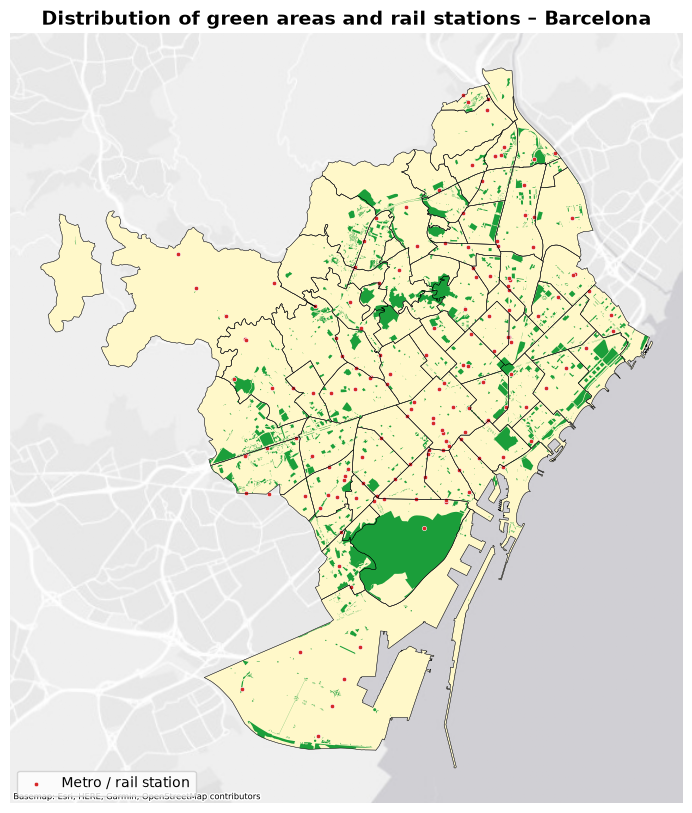

Barris with the LEAST green area (km²):


,barri,district,green_km2
50,Verdun,Nou Barris,0.003103
31,"Vallvidrera, el Tibidabo i les Planes",Sarrià-Sant Gervasi,0.003843
46,Can Peguera,Nou Barris,0.004545
54,Torre Baró,Nou Barris,0.004850
22,la Clota,Horta-Guinardó,0.005414


Barris with the MOST green area (km²):


,barri,district,green_km2
16,el Poble-sec,Sants-Montjuïc,3.223497
17,la Marina del Prat Vermell,Sants-Montjuïc,0.402435
30,Pedralbes,Les Corts,0.348291
18,la Marina de Port,Sants-Montjuïc,0.335939
68,Diagonal Mar i el Front Marítim del Poblenou,Sant Martí,0.335729


In [21]:
fig, ax = plt.subplots(figsize=(10, 10)); ax.set_axis_off()
b.plot(ax=ax, color="#fff8c9", edgecolor="#999", linewidth=0.4)
patches.plot(ax=ax, color="#1b9e3a", linewidth=0)
stations.plot(ax=ax, color="#d62728", markersize=10, marker="o", edgecolor="white", linewidth=0.4, label="Metro / rail station")
b.boundary.plot(ax=ax, color="k", linewidth=0.3)
ax.set_title(f"Distribution of green areas and rail stations – {CFG['CITY']}", fontsize=14, weight="bold")
ax.legend(loc="lower left"); add_basemap(ax, b.crs); save(fig, "obj1_distribution"); plt.show()

print("Barris with the LEAST green area (km²):");  display(top_bottom(b.assign(green_km2=b.green_m2/1e6), "green_km2", ascending=True))
print("Barris with the MOST green area (km²):");   display(top_bottom(b.assign(green_km2=b.green_m2/1e6), "green_km2"))

## 6. Objective 2 – Green coverage by barri (% of barri area)

saved data\outputs\maps\obj2_coverage.png


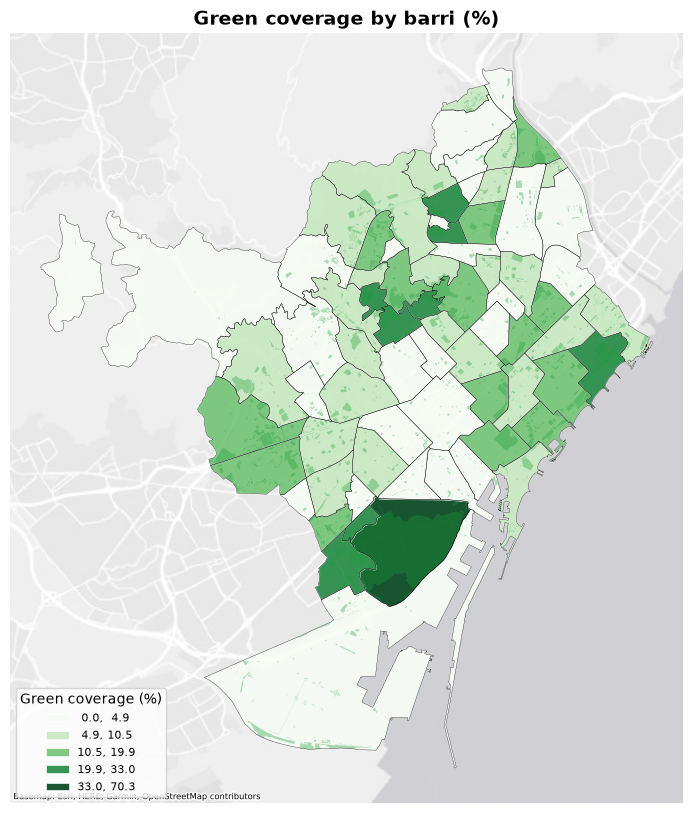

Highest coverage:


,barri,district,green_cover_pct
16,el Poble-sec,Sants-Montjuïc,70.300214
38,el Coll,Gràcia,32.988776
68,Diagonal Mar i el Front Marítim del Poblenou,Sant Martí,27.363076
19,la Font de la Guatlla,Sants-Montjuïc,26.745647
18,la Marina de Port,Sants-Montjuïc,26.480976


Lowest coverage:


,barri,district,green_cover_pct
31,"Vallvidrera, el Tibidabo i les Planes",Sarrià-Sant Gervasi,0.033938
54,Torre Baró,Nou Barris,0.278437
50,Verdun,Nou Barris,1.308584
40,la Vila de Gràcia,Gràcia,1.602869
25,Sants - Badal,Sants-Montjuïc,1.652452


In [22]:
choropleth(b, "green_cover_pct", "Green coverage by barri (%)", cmap="Greens", label="Green coverage (%)", name="obj2_coverage")
print("Highest coverage:"); display(top_bottom(b, "green_cover_pct"))
print("Lowest coverage:");  display(top_bottom(b, "green_cover_pct", ascending=True))

## 7. Objective 3 – Population density

saved data\outputs\maps\obj3_density.png


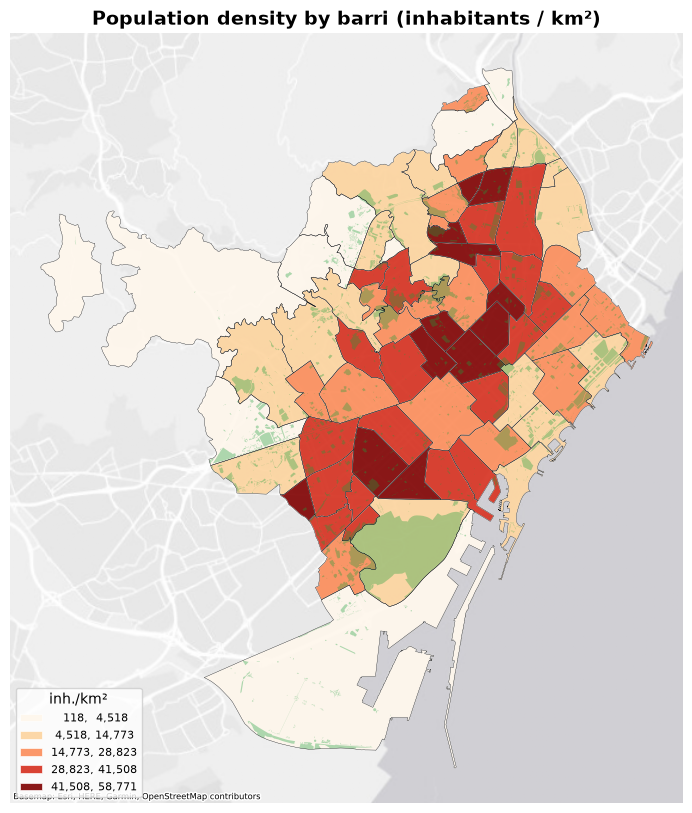

Densest barris:


,barri,district,pop_density_km2
25,Sants - Badal,Sants-Montjuïc,58770.660745
41,el Camp d'en Grassot i Gràcia Nova,Gràcia,54292.301495
50,Verdun,Nou Barris,53871.264236
62,Navas,Sant Andreu,52059.866306
63,el Camp de l'Arpa del Clot,Sant Martí,51770.133914


In [23]:
choropleth(b, "pop_density_km2", "Population density by barri (inhabitants / km²)", cmap="OrRd", label="inh./km²", name="obj3_density", fmt="{:,.0f}")
print("Densest barris:");  display(top_bottom(b, "pop_density_km2"))

## 8. Objective 4.1 – Population per unit of green area

saved data\outputs\maps\obj41_people_per_green.png


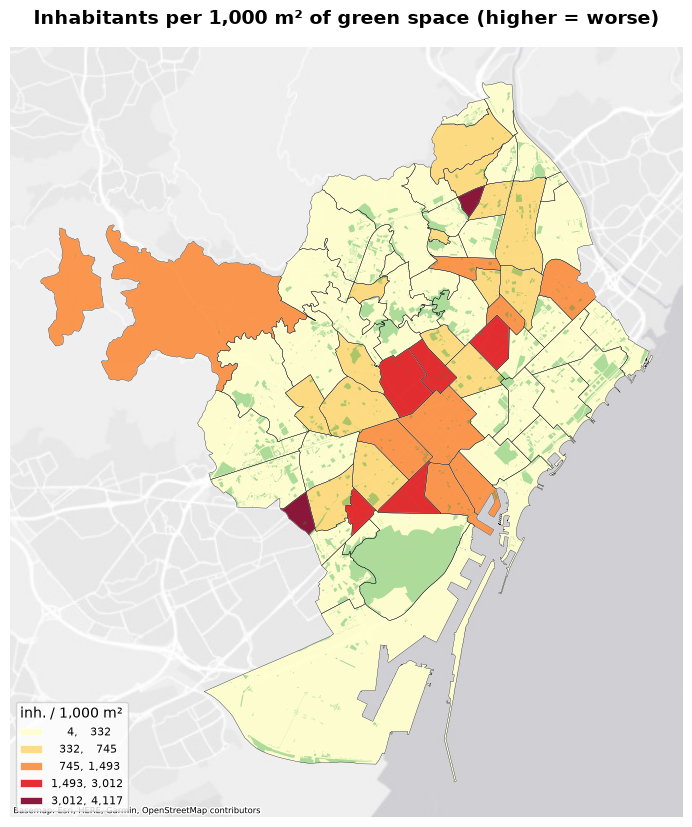

saved data\outputs\maps\obj41_green_per_capita.png


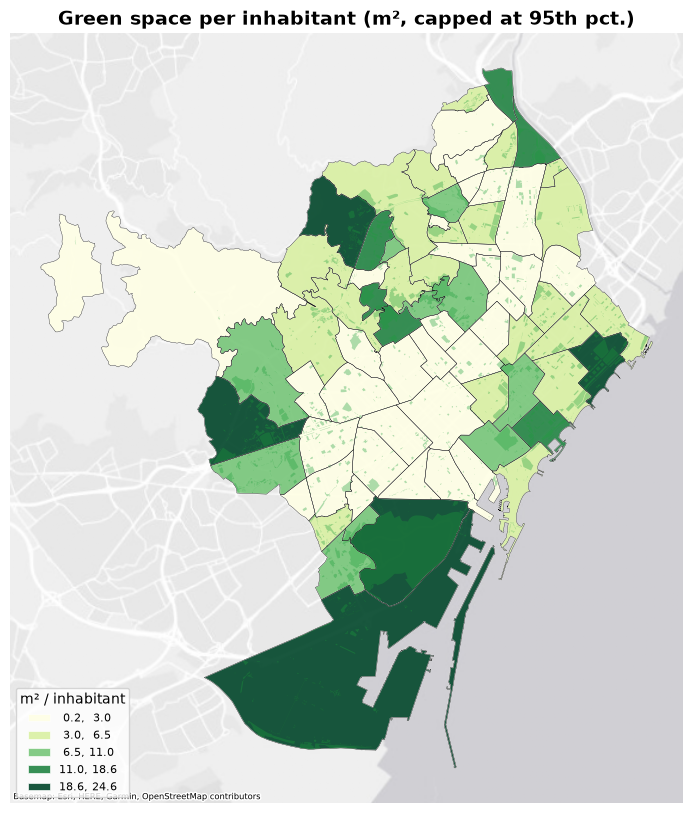

58 of 73 barris are below 9 m²/inhabitant, home to 87% of residents.


,barri,district,green_m2_pp
50,Verdun,Nou Barris,0.242909
25,Sants - Badal,Sants-Montjuïc,0.281170
63,el Camp de l'Arpa del Clot,Sant Martí,0.332040
15,Sant Antoni,Eixample,0.362208
41,el Camp d'en Grassot i Gràcia Nova,Gràcia,0.402672
40,la Vila de Gràcia,Gràcia,0.423130
23,Hostafrancs,Sants-Montjuïc,0.468713
0,el Raval,Ciutat Vella,0.669966


In [24]:
choropleth(b, "people_per_1000m2_green", "Inhabitants per 1,000 m² of green space (higher = worse)", cmap="YlOrRd",
           label="inh. / 1,000 m²", name="obj41_people_per_green", fmt="{:,.0f}")
choropleth(b.assign(g=b.green_m2_pp.clip(upper=b.green_m2_pp.quantile(.95))), "g", "Green space per inhabitant (m², capped at 95th pct.)",
           cmap="YlGn", label="m² / inhabitant", name="obj41_green_per_capita")
below = b[b.green_m2_pp < CFG["WHO_TARGET_M2_PP"]]
print(f"{len(below)} of {len(b)} barris are below {CFG['WHO_TARGET_M2_PP']} m²/inhabitant, "
      f"home to {below.population.sum()/b.population.sum():.0%} of residents.")
display(top_bottom(b, "green_m2_pp", ascending=True, n=8))

## 9. Objective 4.2 – Green space and low-income residents
**Proxy note.** Open Data BCN publishes **average disposable household income per capita by barri**, not an income distribution. The equivalent equity question is therefore asked at barri level: *do lower-income barris get less green space?* Barris below `LOW_INCOME_INDEX` (75 % of the city mean) are flagged *low income*.

Spearman correlation income index vs green m²/inhabitant: rho = -0.02 (p = 0.837)


,barris,population,median_green_m2_pp (pop-weighted),mean_cover_pct
income_quartile,,,,
Q1 (lowest),19.0,320987.0,3.5,8.8
Q2,18.0,346269.0,3.8,11.2
Q3,18.0,519141.0,2.0,11.8
Q4 (highest),18.0,474038.0,2.5,9.2


saved data\outputs\maps\obj42_bivariate.png


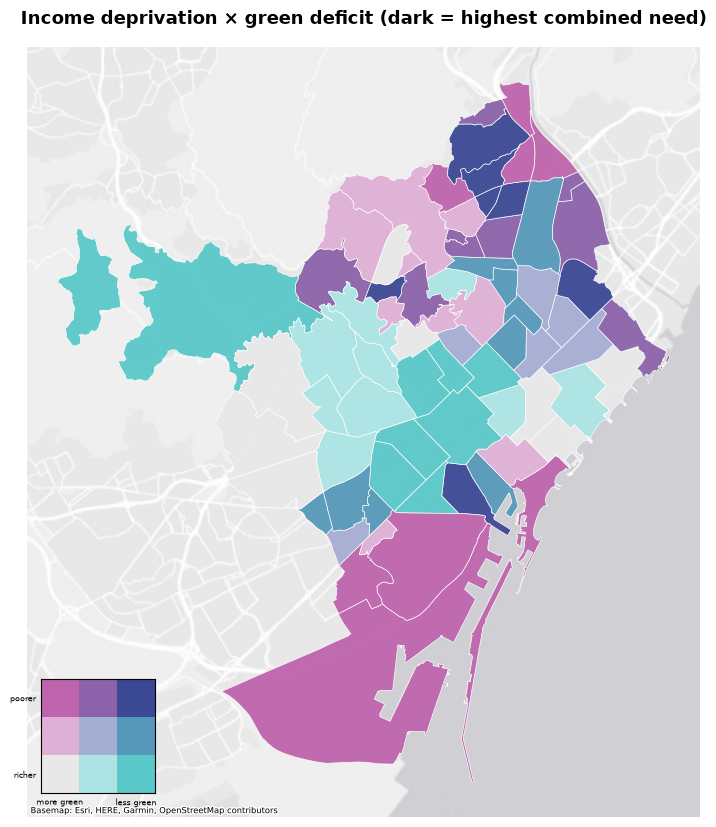

saved data\outputs\maps\obj42_scatter.png


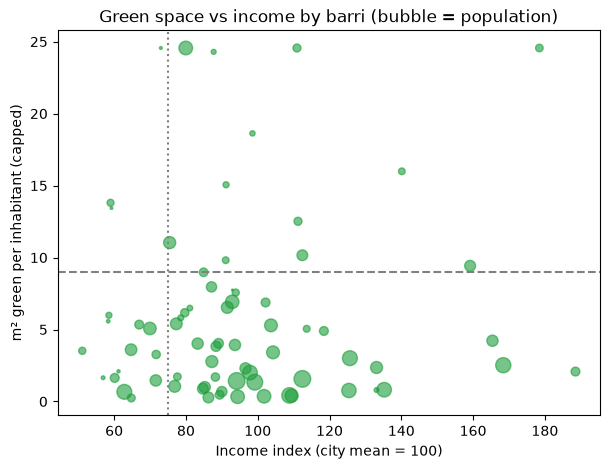

In [26]:
from matplotlib.colors import to_rgb

valid_inc = b.dropna(subset=["rfd_index", "green_m2_pp"])
rho, p = spearmanr(valid_inc["rfd_index"], valid_inc["green_m2_pp"])
print(f"Spearman correlation income index vs green m²/inhabitant: rho = {rho:+.2f} (p = {p:.3f})")

def wmedian(x, w):
    o = np.argsort(x.values); x, w = x.values[o], w.values[o]
    return x[np.searchsorted(np.cumsum(w), 0.5 * w.sum())]

b["income_quartile"] = pd.qcut(b["rfd_index"], 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
grp = (b.groupby("income_quartile", observed=True)
         .apply(lambda d: pd.Series({"barris": len(d), "population": d.population.sum(),
                                      "median_green_m2_pp (pop-weighted)": wmedian(d.green_m2_pp, d.population),
                                      "mean_cover_pct": d.green_cover_pct.mean()}), include_groups=False))
display(grp.round(1))

# Bivariate map: income deprivation x green deficit (dark = poor AND short of green)
terc = lambda s: pd.qcut(s.rank(method="first"), 3, labels=False)
b["bi"] = terc(-b["rfd_index"]) * 3 + terc(-b["green_m2_pp"])            # y = income deprivation, x = green deficit
PAL = ["#e8e8e8", "#ace4e4", "#5ac8c8", "#dfb0d6", "#a5add3", "#5698b9", "#be64ac", "#8c62aa", "#3b4994"]
fig, ax = plt.subplots(figsize=(10, 10)); ax.set_axis_off()
b.plot(column="bi", cmap=ListedColormap(PAL), vmin=0, vmax=8, edgecolor="white", linewidth=0.5, ax=ax, alpha=0.95,
       missing_kwds={"color": "lightgrey"})
add_basemap(ax, b.crs)

legend_img = np.array([to_rgb(c) for c in PAL]).reshape(3, 3, 3)[::-1]      # hex -> RGB numbers
ins = ax.inset_axes([0.02, 0.02, 0.17, 0.17]); ins.imshow(legend_img, origin="upper")
ins.set_xticks([0, 2]); ins.set_xticklabels(["more green", "less green"], fontsize=6)
ins.set_yticks([0, 2]); ins.set_yticklabels(["poorer", "richer"], fontsize=6); ins.tick_params(length=0)
ax.set_title("Income deprivation × green deficit (dark = highest combined need)", fontsize=13, weight="bold")
save(fig, "obj42_bivariate"); plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(b.rfd_index, b.green_m2_pp.clip(upper=b.green_m2_pp.quantile(.95)), s=b.population / 400, alpha=0.6, c="#1b9e3a")
ax.axhline(CFG["WHO_TARGET_M2_PP"], ls="--", c="grey"); ax.axvline(CFG["LOW_INCOME_INDEX"], ls=":", c="grey")
ax.set_xlabel("Income index (city mean = 100)"); ax.set_ylabel("m² green per inhabitant (capped)")
ax.set_title("Green space vs income by barri (bubble = population)"); save(fig, "obj42_scatter"); plt.show()

## 10. Objective 5 – Green Accessibility Score & Ranking

Supply metrics (m², %) say how much green a barri *contains*; they do not say whether the people living there can *reach* it. The score combines four components, each scaled 0–100 (higher = better):

| Component | Definition | Default weight |
|---|---|---|
| `c_percapita` | m² of green per inhabitant (winsorised 5–95 %, min-max) | 0.30 |
| `c_prox300` | % of residents (building-footprint-weighted) within **300 m** of a green patch ≥ **0.5 ha** | 0.35 |
| `c_large1km` | % of residents within **1 km** of a green patch ≥ **5 ha** (district-scale park) | 0.15 |
| `c_coverage` | % of barri area that is green (winsorised 5–95 %, min-max) | 0.20 |

Proximity is the heaviest component because it measures *access*, not just *supply*. Weights are a policy choice, so §10.5 tests how much the ranking depends on them.

**Priority index** (separate from the score): combines *access need* (100 − score), population density and income deprivation to point at where an extra hectare of green helps most people with the fewest alternatives.

**Limitations:** distances are straight-line (Euclidean), not walking-network; residents are located through OSM building footprints (a proxy that ignores building height).

### 10.1 Where do residents live? (sampling points)

In [27]:
def sample_points_grid(step):
    minx, miny, maxx, maxy = b.total_bounds
    xx, yy = np.meshgrid(np.arange(minx + step / 2, maxx, step), np.arange(miny + step / 2, maxy, step))
    pts = gpd.GeoDataFrame(geometry=gpd.points_from_xy(xx.ravel(), yy.ravel()), crs=b.crs)
    pts["w"] = 1.0
    return pts

def get_points():
    if CFG["POINTS"] == "buildings":
        try:
            pts = cached_gdf("osm_building_centroids", fetch_buildings).to_crs(b.crs)
            PROV["sources"]["buildings"] = {"api": "Overpass (OpenStreetMap)", "tags": "building=*", "weight": "footprint m²"}
            return pts
        except Exception as e:
            print(f"Buildings unavailable ({type(e).__name__}: {e}) -> falling back to grid sampling")
    PROV["sources"]["points"] = f"regular grid {CFG['GRID_STEP_M']} m (equal weight)"
    return sample_points_grid(CFG["GRID_STEP_M"])

pts = get_points()
pts = gpd.sjoin(pts, b[["barri_code", "geometry"]], predicate="within", how="inner").drop(columns="index_right")
pts = pts[~shapely.intersects(np.asarray(pts.geometry.values), green_union)]       # nobody lives inside a park
print(f"sample points: {len(pts):,} across {pts.barri_code.nunique()} barris")

[api]   osm_building_centroids: 66,086 features
sample points: 64,883 across 73 barris


### 10.2 Proximity components

In [28]:
def reach(points, patch_gdf, min_area, dist):
    sel = patch_gdf[patch_gdf["area_m2"] >= min_area]
    if sel.empty: return np.zeros(len(points), dtype=bool)
    buf = unary(sel.geometry.buffer(dist)); shapely.prepare(buf)
    return shapely.intersects(np.asarray(points.geometry.values), buf)

pts["near_small"] = reach(pts, patches, CFG["NEAR_MIN_M2"], CFG["NEAR_DIST_M"])
pts["near_large"] = reach(pts, patches, CFG["LARGE_MIN_M2"], CFG["LARGE_DIST_M"])

def wshare(flag):
    return (pts[flag] * pts["w"]).groupby(pts["barri_code"]).sum() / pts["w"].groupby(pts["barri_code"]).sum()

prox = pd.DataFrame({"share_300m_05ha": wshare("near_small"), "share_1km_5ha": wshare("near_large")}).reset_index()
b = b.drop(columns=[c for c in ("share_300m_05ha", "share_1km_5ha") if c in b.columns]).merge(prox, on="barri_code", how="left")
b[["share_300m_05ha", "share_1km_5ha"]] = b[["share_300m_05ha", "share_1km_5ha"]].fillna(0)   # no sample points = no access
print(f"Residents within {CFG['NEAR_DIST_M']} m of >=0.5 ha green: "
      f"{np.average(b.share_300m_05ha, weights=b.population):.0%} (population-weighted)")

Residents within 300 m of >=0.5 ha green: 69% (population-weighted)


### 10.3 Scoring, ranking, priority

In [29]:
def winsor_minmax(s, lo=0.05, hi=0.95):
    s = pd.Series(s, dtype=float); a, c = s.quantile(lo), s.quantile(hi)
    return ((s.clip(a, c) - a) / (c - a) * 100) if c > a else s * 0

def components(df):
    return pd.DataFrame({"c_percapita": winsor_minmax(df["green_m2_pp"]),
                         "c_prox300":   df["share_300m_05ha"] * 100,
                         "c_large1km":  df["share_1km_5ha"] * 100,
                         "c_coverage":  winsor_minmax(df["green_cover_pct"])}, index=df.index)

def accessibility_score(comp, weights):
    w = pd.Series(weights, dtype=float); w = w / w.sum()
    return (comp[w.index] * w).sum(axis=1)

def priority_index(df, score, pw):
    need  = 100 - score
    dens  = df["pop_density_km2"].rank(pct=True) * 100
    inc   = (1 - df["rfd_index"].rank(pct=True)) * 100
    w = pd.Series(pw, dtype=float); w = w / w.sum()
    return w["access_need"] * need + w["density"] * dens + w["income_need"] * inc.fillna(inc.median())

def rank_stability(comp, base_w, n=2000, concentration=50, seed=42):
    rng = np.random.default_rng(seed); keys = list(base_w)
    alpha = np.array([base_w[k] for k in keys], float); alpha = alpha / alpha.sum() * concentration
    W = rng.dirichlet(alpha, size=n)                          # n random weightings around the base weights
    scores = comp[keys].values @ W.T                          # (barris, n)
    ranks = (-scores).argsort(axis=0).argsort(axis=0) + 1
    return pd.DataFrame({"rank_p05": np.percentile(ranks, 5, axis=1), "rank_median": np.median(ranks, axis=1),
                         "rank_p95": np.percentile(ranks, 95, axis=1)}, index=comp.index)

comp = components(b)
b = b.drop(columns=[c for c in b.columns if c.startswith("c_")], errors="ignore").join(comp)
b["access_score"]   = accessibility_score(comp, CFG["WEIGHTS"])
b["access_rank"]    = b["access_score"].rank(ascending=False, method="min").astype(int)     # 1 = best access
b["access_tier"]    = pd.qcut(b["access_score"], 5, labels=["Very low", "Low", "Medium", "High", "Very high"])
b["priority_index"] = priority_index(b, b["access_score"], CFG["PRIORITY_WEIGHTS"])
b["priority_rank"]  = b["priority_index"].rank(ascending=False, method="min").astype(int)   # 1 = most urgent
b["meets_who_9m2"]  = b["green_m2_pp"] >= CFG["WHO_TARGET_M2_PP"]

cols = ["access_rank", "barri", "district", "access_score", "access_tier", "green_m2_pp", "share_300m_05ha", "share_1km_5ha", "green_cover_pct", "population"]
ranking = b.sort_values("access_rank")[cols].reset_index(drop=True)
print("TOP 10 – best green accessibility");    display(ranking.head(10).round(2))
print("BOTTOM 10 – worst green accessibility"); display(ranking.tail(10).round(2))

TOP 10 – best green accessibility


,access_rank,barri,district,access_score,access_tier,green_m2_pp,share_300m_05ha,share_1km_5ha,green_cover_pct,population
0,1,Diagonal Mar i el Front Marítim del Poblenou,Sant Martí,100.00,Very high,24.96,1.00,1.00,27.36,13453
1,2,el Poble-sec,Sants-Montjuïc,95.82,Very high,83.13,0.88,1.00,70.30,38778
2,3,el Coll,Gràcia,88.21,Very high,15.05,1.00,1.00,32.99,7740
3,4,la Vall d'Hebron,Horta-Guinardó,83.10,Very high,18.62,1.00,1.00,14.69,5874
4,5,la Vila Olímpica del Poblenou,Sant Martí,80.77,Very high,15.99,0.99,1.00,16.15,9338
5,6,Pedralbes,Les Corts,79.90,Very high,28.71,0.74,1.00,12.97,12130
6,7,la Salut,Gràcia,79.71,Very high,12.52,0.86,1.00,26.04,13491
7,8,Montbau,Horta-Guinardó,79.71,Very high,24.29,0.93,0.92,6.12,5174
8,9,la Trinitat Vella,Sant Andreu,79.44,Very high,13.80,1.00,1.00,17.58,10286
9,10,Can Baró,Horta-Guinardó,79.27,Very high,9.82,0.99,1.00,24.07,9421


BOTTOM 10 – worst green accessibility


,access_rank,barri,district,access_score,access_tier,green_m2_pp,share_300m_05ha,share_1km_5ha,green_cover_pct,population
63,64,el Raval,Ciutat Vella,24.06,Very low,0.67,0.37,0.66,2.78,45671
64,65,el Bon Pastor,Sant Andreu,22.99,Very low,3.27,0.38,0.35,2.52,14434
65,66,el Barri Gòtic,Ciutat Vella,20.10,Very low,0.89,0.15,0.90,2.67,24460
66,67,la Vila de Gràcia,Gràcia,16.98,Very low,0.42,0.29,0.45,1.60,50048
67,68,Sant Antoni,Eixample,16.94,Very low,0.36,0.12,0.84,1.72,38269
68,69,el Camp d'en Grassot i Gràcia Nova,Gràcia,15.58,Very low,0.40,0.28,0.35,2.19,35319
69,70,la Dreta de l'Eixample,Eixample,12.31,Very low,0.82,0.26,0.18,1.70,44105
70,71,Torre Baró,Nou Barris,10.76,Very low,1.65,0.25,0.02,0.28,2939
71,72,l'Antiga Esquerra de l'Eixample,Eixample,9.24,Very low,0.76,0.18,0.10,2.66,42751
72,73,"Vallvidrera, el Tibidabo i les Planes",Sarrià-Sant Gervasi,1.84,Very low,0.80,0.03,0.02,0.03,4831


### 10.4 Ranking maps & charts

saved data\outputs\maps\obj5_score_map.png


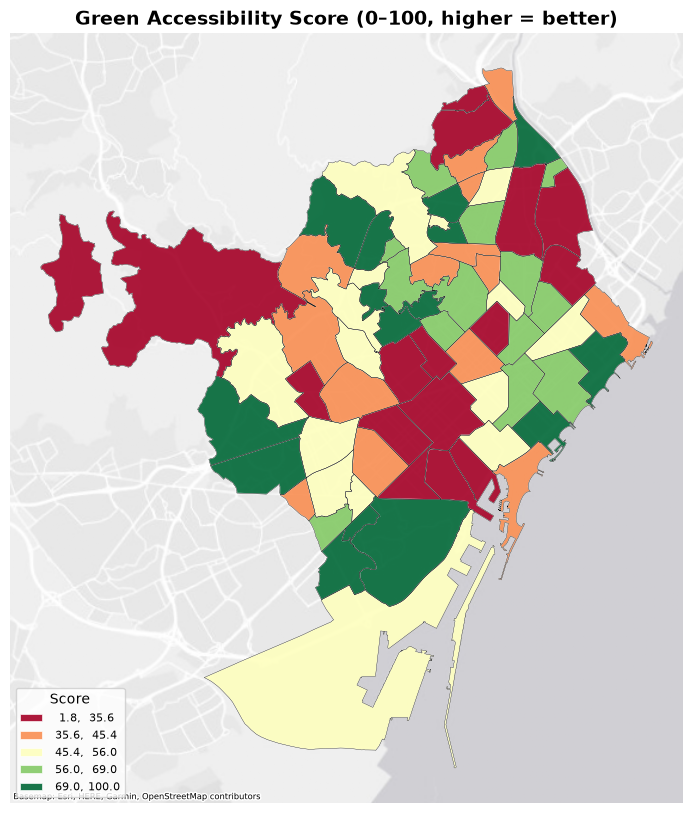

saved data\outputs\maps\obj5_priority_map.png


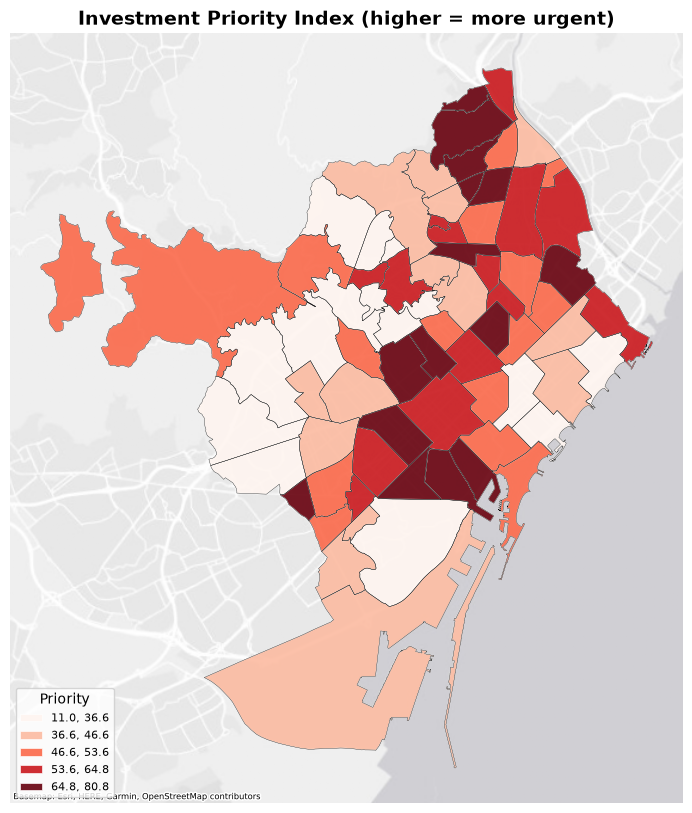

saved data\outputs\maps\obj5_ranking_bars.png


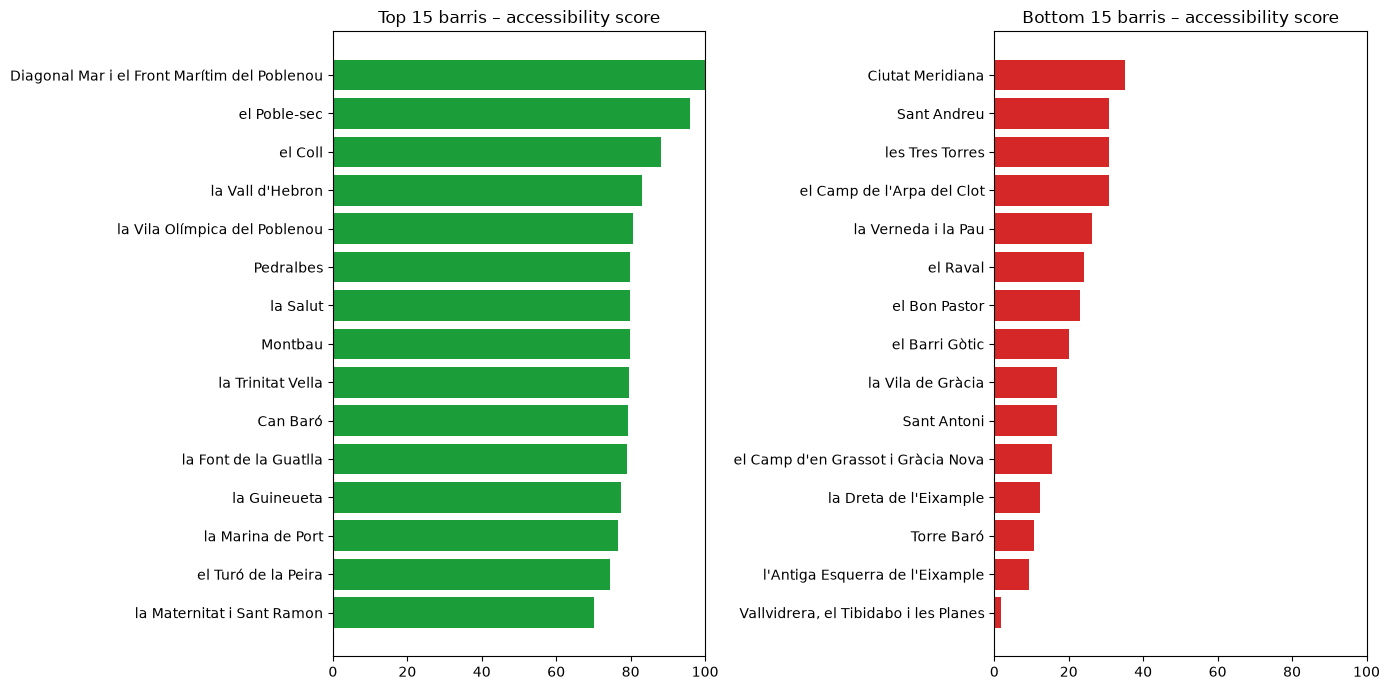

saved data\outputs\maps\obj5_components_bottom10.png


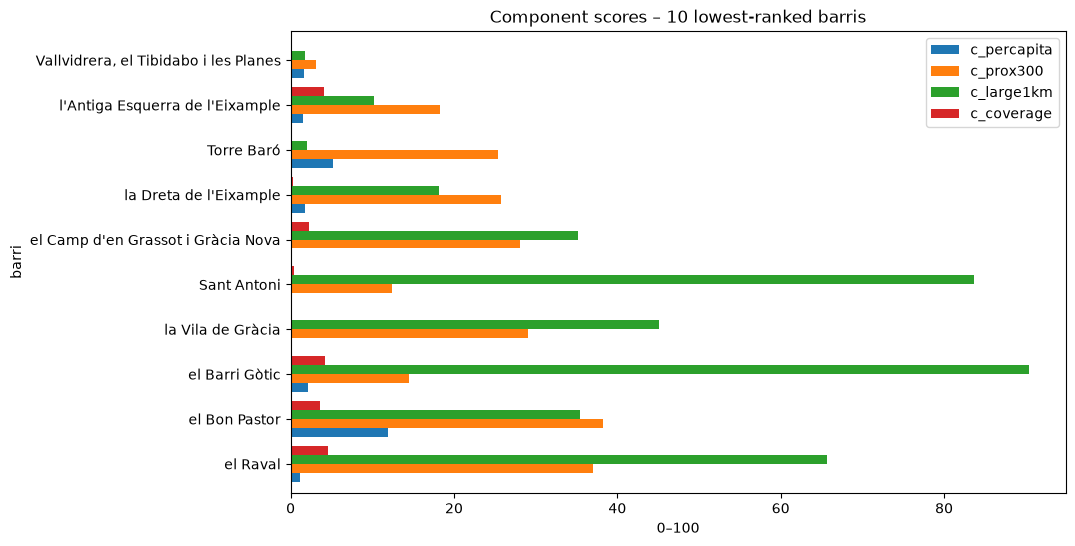

,population,score_pop_weighted,m2_per_capita
district,,,
Sants-Montjuïc,185963.0,66.5,22.7
Les Corts,82154.0,62.8,8.9
Horta-Guinardó,175550.0,59.7,6.4
Nou Barris,174215.0,53.4,3.6
Sant Martí,242752.0,52.2,5.0
Sant Andreu,151799.0,41.7,2.7
Sarrià-Sant Gervasi,149804.0,41.0,3.8
Gràcia,122928.0,32.5,3.3
Ciutat Vella,106446.0,31.1,3.0


In [30]:
choropleth(b, "access_score", "Green Accessibility Score (0–100, higher = better)", cmap="RdYlGn", scheme="Quantiles",
           label="Score", name="obj5_score_map", overlay_green=False)
choropleth(b, "priority_index", "Investment Priority Index (higher = more urgent)", cmap="Reds", scheme="Quantiles",
           label="Priority", name="obj5_priority_map", overlay_green=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharex=True)
for ax, d, ttl, col in ((axes[0], ranking.head(15)[::-1], "Top 15", "#1b9e3a"), (axes[1], ranking.tail(15)[::-1], "Bottom 15", "#d62728")):
    ax.barh(d["barri"], d["access_score"], color=col); ax.set_title(f"{ttl} barris – accessibility score"); ax.set_xlim(0, 100)
plt.tight_layout(); save(fig, "obj5_ranking_bars"); plt.show()

# Which component drags each of the 10 lowest-ranked barris down?
low10 = b.sort_values("access_rank").tail(10).set_index("barri")[list(CFG["WEIGHTS"])]
ax = low10.plot(kind="barh", stacked=False, figsize=(10, 6), width=0.8); ax.set_title("Component scores – 10 lowest-ranked barris"); ax.set_xlabel("0–100")
save(ax.get_figure(), "obj5_components_bottom10"); plt.show()

# By district
dist = (b.groupby("district").apply(lambda d: pd.Series({"population": d.population.sum(),
        "score_pop_weighted": np.average(d.access_score, weights=d.population), "m2_per_capita": d.green_m2.sum() / d.population.sum()}),
        include_groups=False).sort_values("score_pop_weighted", ascending=False))
display(dist.round(1))

### 10.5 How robust is the ranking? (weight sensitivity)
2,000 random weightings drawn around the base weights (Dirichlet). Narrow rank ranges = the barri's position does not depend on the policy choice of weights.

Median 90% rank range: 6 positions | barris whose rank moves >10 positions: 9
saved data\outputs\maps\obj5_rank_stability.png


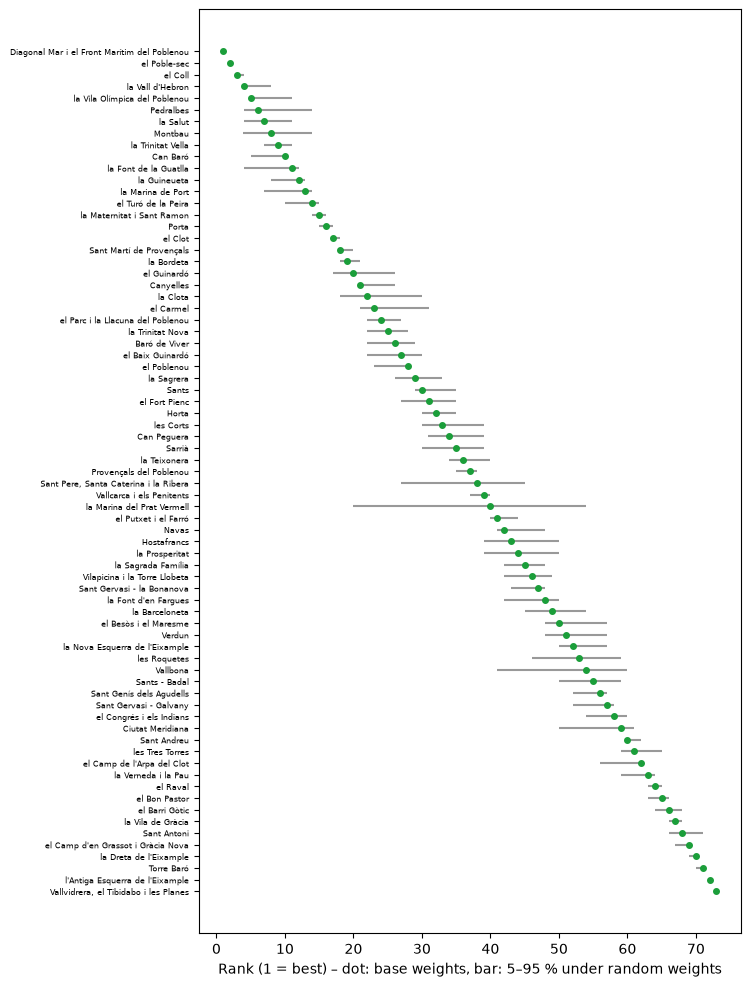

Spearman(score, m² per capita) = 0.78  |  barris whose rank differs by >15 places from a per-capita-only ranking: 19
Spearman(score, income index) = -0.00 (p=0.995)


In [31]:
stab = rank_stability(comp, CFG["WEIGHTS"])
b = b.drop(columns=[c for c in stab.columns if c in b.columns]).join(stab)
b["rank_range90"] = b["rank_p95"] - b["rank_p05"]
print(f"Median 90% rank range: {b['rank_range90'].median():.0f} positions "
      f"| barris whose rank moves >10 positions: {(b['rank_range90'] > 10).sum()}")

o = b.sort_values("access_rank")
fig, ax = plt.subplots(figsize=(7, 12))
ax.hlines(range(len(o)), o.rank_p05, o.rank_p95, color="#999")
ax.plot(o.access_rank, range(len(o)), "o", color="#1b9e3a", ms=4)
ax.set_yticks(range(len(o))); ax.set_yticklabels(o.barri, fontsize=6); ax.invert_yaxis()
ax.set_xlabel("Rank (1 = best) – dot: base weights, bar: 5–95 % under random weights"); save(fig, "obj5_rank_stability"); plt.show()

# Does the score tell us something the simple m²-per-capita metric does not?
rho_pc, _ = spearmanr(b.access_score, b.green_m2_pp)
print(f"Spearman(score, m² per capita) = {rho_pc:.2f}  |  barris whose rank differs by >15 places from a per-capita-only ranking: "
      f"{(abs(b.access_rank - b.green_m2_pp.rank(ascending=False, method='min')) > 15).sum()}")
rho_i, p_i = spearmanr(b.dropna(subset=['rfd_index']).access_score, b.dropna(subset=['rfd_index']).rfd_index)
print(f"Spearman(score, income index) = {rho_i:+.2f} (p={p_i:.3f})")

### 10.6 Priority list for planners

In [32]:
pl = (b.sort_values("priority_rank")[["priority_rank", "barri", "district", "priority_index", "access_score", "access_rank", "pop_density_km2", "rfd_index", "population"]]
        .reset_index(drop=True))
display(pl.head(15).round(1))

no_access = (1 - b.share_300m_05ha) * b.population
print(f"Estimated residents without a ≥0.5 ha green space within {CFG['NEAR_DIST_M']} m: {no_access.sum():,.0f} "
      f"({no_access.sum()/b.population.sum():.0%} of {b.population.sum():,.0f}) – an estimate (area-proxied, straight-line)")

,priority_rank,barri,district,priority_index,access_score,access_rank,pop_density_km2,rfd_index,population
0,1,el Raval,Ciutat Vella,80.8,24.1,64,41508.1,62.8,45671
1,2,Verdun,Nou Barris,75.6,40.0,51,53871.3,64.8,12774
2,3,el Camp d'en Grassot i Gràcia Nova,Gràcia,72.7,15.6,69,54292.3,109.4,35319
3,4,Sant Antoni,Eixample,72.0,16.9,68,47591.5,101.8,38269
4,5,Ciutat Meridiana,Nou Barris,71.5,35.2,59,28823.0,51.1,10857
5,6,Sants - Badal,Sants-Montjuïc,71.1,38.0,55,58770.7,86.3,24366
6,7,el Barri Gòtic,Ciutat Vella,70.8,20.1,66,29990.4,84.7,24460
7,8,Torre Baró,Nou Barris,70.0,10.8,71,1687.3,56.9,2939
8,9,la Verneda i la Pau,Sant Martí,69.0,26.3,63,25885.7,76.9,29250
9,10,la Prosperitat,Nou Barris,69.0,45.5,44,45099.0,71.6,26664


Estimated residents without a ≥0.5 ha green space within 300 m: 512,755 (31% of 1,660,435) – an estimate (area-proxied, straight-line)


## 11. Auto-generated findings
Text below is computed from the results so it stays truthful when data or parameters change.

In [34]:
best, worst = b.loc[b.access_score.idxmax()], b.loc[b.access_score.idxmin()]
lines = [
 f"- {len(b)} barris analysed; {b.population.sum():,.0f} inhabitants; green space = {b.green_m2.sum()/1e6:.2f} km² ({b.green_m2.sum()/b.area_m2.sum():.1%} of the territory).",
 f"- City-wide green per inhabitant: {b.green_m2.sum()/b.population.sum():.1f} m² (guide value {CFG['WHO_TARGET_M2_PP']} m²); "
 f"{(~b.meets_who_9m2).sum()} barris fall below it, housing {b.loc[~b.meets_who_9m2,'population'].sum()/b.population.sum():.0%} of residents.",
 f"- Best-ranked barri: {best.barri} ({best.access_score:.0f}/100). Lowest-ranked: {worst.barri} ({worst.access_score:.0f}/100).",
 f"- Income vs green per capita: Spearman rho = {rho:+.2f}; income vs accessibility score: rho = {rho_i:+.2f}.",
 f"- Highest investment priority: {', '.join(pl.head(5).barri)}.",
 f"- Ranking robustness: median 90% rank range = {b.rank_range90.median():.0f} positions.",
]
print("\n".join(lines))

- 73 barris analysed; 1,660,435 inhabitants; green space = 9.98 km² (9.8% of the territory).
- City-wide green per inhabitant: 6.0 m² (guide value 9 m²); 58 barris fall below it, housing 87% of residents.
- Best-ranked barri: Diagonal Mar i el Front Marítim del Poblenou (100/100). Lowest-ranked: Vallvidrera, el Tibidabo i les Planes (2/100).
- Income vs green per capita: Spearman rho = -0.02; income vs accessibility score: rho = -0.00.
- Highest investment priority: el Raval, Verdun, el Camp d'en Grassot i Gràcia Nova, Sant Antoni, Ciutat Meridiana.
- Ranking robustness: median 90% rank range = 6 positions.


## 12. Export (artefacts for the next phase)
Outputs are written with a provenance file (sources, parameters, retrieval time) so any number can be traced back to its API call.

In [35]:
export_cols = ["barri_code", "barri", "district", "population", "area_m2", "green_m2", "green_cover_pct", "pop_density_km2", "green_m2_pp",
               "people_per_1000m2_green", "income_eur_pc", "rfd_index", "low_income", "n_stations", "share_300m_05ha", "share_1km_5ha",
               *CFG["WEIGHTS"], "access_score", "access_rank", "access_tier", "priority_index", "priority_rank",
               "rank_p05", "rank_median", "rank_p95", "meets_who_9m2"]
res = b[export_cols + ["geometry"]].copy()
res["access_tier"] = res["access_tier"].astype(str)
res["barri_code"] = res["barri_code"].astype(int)
res.to_file(OUT / "barri_green_metrics.gpkg", layer="barris", driver="GPKG")
patches.to_file(OUT / "barri_green_metrics.gpkg", layer="green_patches", driver="GPKG")
res.drop(columns="geometry").sort_values("access_rank").to_csv(OUT / "barri_green_ranking.csv", index=False)
res.to_crs(CFG["CRS_WGS84"]).to_file(OUT / "barri_green_metrics.geojson", driver="GeoJSON")

PROV["parameters"] = {k: v for k, v in CFG.items() if k not in ("CKAN",)}
PROV["row_counts"] = {"barris": len(b), "green_patches": len(patches), "sample_points": int(len(pts))}
(OUT / "provenance.json").write_text(json.dumps(PROV, indent=2, default=str), encoding="utf-8")
print("written:", *sorted(p.name for p in OUT.iterdir() if p.is_file()), sep="\n  ")

written:
  barri_green_metrics.geojson
  barri_green_metrics.gpkg
  barri_green_ranking.csv
  provenance.json


### Optional: interactive map

In [37]:
try:
    tiles = BASEMAP_URL if BASEMAP_URL else "OpenStreetMap"
    extra = {"attr": "Basemap: Esri, HERE, Garmin, OpenStreetMap contributors"} if BASEMAP_URL else {}
    m = b.to_crs(CFG["CRS_WGS84"]).explore(
        column="access_score", cmap="RdYlGn", legend=True, tiles=tiles,
        tooltip=["barri", "district", "access_score", "access_rank", "green_m2_pp", "priority_rank"],
        **extra)
    display(m)
except Exception as e:
    print("interactive map skipped:", type(e).__name__, e)

## 13. Limitations & open decisions

**Data**
- Income is an **area average** (no household distribution), so "low-income residents" is approximated at barri level – an ecological-fallacy risk (poor residents in a rich barri are invisible).
- Population and income reference years may differ; both are printed in `provenance.json`. At this run, they are the same.

**Method**
- Euclidean distances; no walking network, barriers (ring roads, rail) or park entrances.
- All green counted equally (no quality, safety, opening hours, tree canopy). Candidate extensions: canopy/NDVI, park amenities, walking-network isochrones.
- Large peri-urban forest (Collserola) is **excluded by default** (`INCLUDE_FOREST=False`); including it changes the ranking of the hillside barris.

## 14. Path to production
The notebook is organised so each stage becomes a module: `ingest` (§2–3: CKAN/Overpass clients, caching, schema checks), `process` (§4, §10.1–10.2), `score` (§10.3: `components`, `accessibility_score`, `priority_index`, `rank_stability`), `publish` (§12 outputs). Next phase: package + tests, scheduled refresh, PostGIS storage, REST API and web dashboard, containerised deployment, data-quality monitoring and a city-agnostic config so other European cities can be added.